# SONARA hyperparameter tuning for the system model (validation only)

Run 2 chose setup **B8** (MobileNetV3-Small, ImageNet weights, no normalization, loudness augmentation), but its training settings were common defaults set by hand. This notebook replaces "it is the default" with a search, **before** the final evaluation opens the locked test set.

## What is tuned, and what is not

**Tuned** (22 settings that control training). The ranges are as wide as is sensible for this model and a one-day budget on a T4; each one brackets the Run 2 value on both sides. Settings that are numbers in a natural order are searched as ordered ranges with a step, so the search can learn "more is better up to a point".

| Group | Setting | Range searched | Run 2 value |
| :- | :- | :- | :- |
| Optimizer | optimizer | AdamW, Adam, or SGD with Nesterov momentum 0.9 | AdamW |
| | learning rate, AdamW and Adam | 0.000001 to 0.01 (log scale) | 0.0003 |
| | learning rate, SGD | 0.0001 to 0.3 (log scale; SGD needs larger steps) | — |
| | weight decay | 0.0000001 to 0.3 (log scale) | 0.01 |
| | batch size | 8, 16, 32, 64, 128 | 16 |
| | class weights in the loss | balanced (by class counts) or none | balanced |
| Schedule | learning-rate schedule | cosine decay, constant, or halve when validation loss stops improving | cosine |
| | warm-up epochs (cosine and constant) | 0 to 5 | 2 |
| | maximum epochs | 20 to 100, step 10 | 40 |
| | early-stopping patience | 5 to 20 epochs, step 5 | 10 |
| Regularization | dropout before the last layer | 0.0 to 0.7 | 0.2 |
| | label smoothing | 0 to 0.2, step 0.01 | 0.02 |
| | mixup strength | 0 to 1.0, step 0.1 | 0.2 |
| Augmentation | loudness change | 0 to ±24 dB, step 3 | ±12 dB |
| | share of clips given a loudness change | 0.25 to 1.0, step 0.125 | 1.0 |
| | largest time shift | 0 to 2.0 s, step 0.25 | 0.5 s |
| | share of clips given a time shift | 0 to 1.0, step 0.25 | 0.5 |
| | time-mask probability | 0 to 0.8, step 0.1 | 0.4 |
| | largest time mask (share of the clip) | 2.5% to 40%, step 2.5% | 12.5% |
| | number of time masks | 1 to 3 | 1 |
| | frequency-mask probability | 0 to 0.8, step 0.1 | 0.4 |
| | largest frequency mask (share of the 64 bands) | 2.5% to 40%, step 2.5% | 12.5% |
| | number of frequency masks | 1 to 3 | 1 |

**Not tuned, on purpose:**

- **Random seeds.** The seed decides the data split, the starting weights, the batch order and every augmentation draw. Choosing the seed that scores best would be cherry-picking. Seeds are used only to measure how much results vary.
- **Model architecture and input features** (MobileNetV3-Small, ImageNet weights, 16 kHz, 5 s, 64 mel bands). These were chosen in Run 2 and are tied to the gateway hardware and the sensing nodes.
- **The decision threshold.** It is not a training setting; each run sets it on its own validation clips. Two operating points are checked, as in the final evaluation: the threshold that catches 90% of Distress clips and the one that catches 95%.
- **Small internal constants**: SGD momentum (0.9, the usual value), the plateau schedule's halving factor and its 2-epoch wait, the cosine schedule's floor (2% of the starting rate), and the smallest mask (5 frames, 3 bands). They change the same things as settings that are searched.

## Why a search and not every combination

With 22 settings, even three values each gives 3^22, about 31 billion combinations; at about 6 minutes per training run that is roughly 360,000 years of GPU time. The standard alternative is a guided search: **Optuna** with the Tree-structured Parzen Estimator (Bergstra et al., 2011; Akiba et al., 2019). It tries settings at random at first, then concentrates on the regions that score well, and it models settings jointly so that related ones (for example learning rate and batch size) are chosen together. Random and guided search find good settings far more efficiently than a grid (Bergstra & Bengio, 2012). Trials that are clearly worse than the others at the same epoch are stopped early (median pruning).

**Budget.** The search runs up to `N_TRIALS = 200` trials or `SEARCH_HOURS = 20` hours of training, whichever comes first, then the confirmation stage takes roughly another 2 to 4 hours.

## Stages and rules

| Stage | What happens | Data |
| :- | :- | :- |
| 1. Search | `N_TRIALS` settings are tried, each trained once. Score: validation ROC-AUC. | One split used **only** for the search (`TUNE_SEED = 1`) |
| 2. Confirm | The 3 best settings from the search, **and the Run 2 settings**, are each trained on the three Run 2 splits (seeds 7, 21, 42), and given the loudness check at both operating points (90% and 95% recall). | Validation clips of those splits |
| 3. Decide | A tuned setting replaces the Run 2 settings **only if** its mean validation ROC-AUC is higher, it is higher on at least 2 of 3 seeds, and its recall and false-alarm rate stay within 0.10 at ±10 dB at both operating points. Otherwise the Run 2 settings are kept. | — |

The locked test set (id `bf636617`) and PVSD are never loaded. The search split and the confirmation splits differ, so the search cannot simply memorize the clips it is later judged on. The decision is written to `chosen_system_model_config.json`, which the final evaluation notebook reads.

**Before running:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all, and allow Google Drive access. Expect up to about a day: the search stops after 200 trials or 20 hours of training, and the confirmation stage adds 2 to 4 hours. Free Colab sessions usually end sooner than that; the search is saved after every trial, so after a disconnect just run the notebook again and it continues where it stopped.

## 1. Setup and configuration

In [1]:
!pip -q install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.1 MB/s eta 0:00:00


In [2]:
import os, re, copy, glob, hashlib, json, math, random, time
from math import gcd

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import resample_poly
import optuna

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchvision
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau, LambdaLR

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__, "| optuna", optuna.__version__)
if device.type == "cpu":
    print("WARNING: no GPU. Switch the Colab runtime to a T4 GPU before running the search.")

Device: cuda | torch 2.11.0+cu130 | optuna 5.0.0


In [3]:
# ---- Data and outputs ----------------------------------------------------
REPO_URL = "https://github.com/tagalogclark123-cmyk/SONARA-GITHUB.git"
REPO_DIR = "/content/SONARA-GITHUB"
SAVE_TO_DRIVE = True
OUT_DIR = "/content/drive/MyDrive/SONARA/hyperparameter_tuning" if SAVE_TO_DRIVE else "/content/hyperparameter_tuning"
SMARTEARS_ROOT = "Smartears"
LABEL_MAP = {"Healthy": "Normal", "None": "Noise", "Sick": "Distress"}

# ---- Protocol ----------------------------------------------------------------
LOCK_SEED = 2026
EXPECTED_LOCK_ID = "bf636617"
TUNE_SEED = 1                 # train/validation split used only by the search
CONFIRM_SEEDS = [7, 21, 42]   # the Run 2 splits, used to confirm the best settings
N_TRIALS = 200                # most settings tried in the search
SEARCH_HOURS = 20.0           # most hours of training spent on the search, added up across sessions
TOP_K = 3                     # best search settings carried into the confirmation stage
GROUP_BY = "recording"
TARGET_RECALLS = [0.90, 0.95]  # operating points checked in the confirmation stage (same as the final evaluation)
LEVEL_TOLERANCE = 0.10        # loudness condition from the Run 2 selection rule
STUDY_NAME = "sonara_b8_wide_v2"

# ---- Fixed input (same as Run 2) ---------------------------------------------
SAMPLE_RATE = 16000
CROP_SEC = 5.0
N_FFT, HOP_LENGTH, N_MELS = 400, 160, 64

# ---- The Run 2 settings of B8 (the reference the search must beat) ----------
RUN2_B8 = {"model": "mobilenetv3_small", "pretrained": True, "norm": "none",
           "optimizer": "adamw", "lr": 3e-4, "weight_decay": 1e-2, "batch_size": 16,
           "schedule": "cosine", "warmup": 2, "max_epochs": 40, "head_dropout": 0.2,
           "label_smoothing": 0.02, "mixup": 0.2, "gain_db": 12.0, "gain_prob": 1.0,
           "shift_sec": 0.5, "shift_prob": 0.5, "time_mask_prob": 0.4, "freq_mask_prob": 0.4,
           "patience": 10, "class_weighting": "balanced", "time_mask_frac": 0.125, "n_time_masks": 1,
           "freq_mask_frac": 0.125, "n_freq_masks": 1}

QUICK_RUN = None              # e.g. 40 = 40 clips per class, 2 epochs, 3 trials (code check only)

CROP_SAMPLES = int(round(CROP_SEC * SAMPLE_RATE))
N_FRAMES = CROP_SAMPLES // HOP_LENGTH
NUM_WORKERS = 2 if os.name == "posix" else 0
SEARCH_EPOCH_CAP = None
if QUICK_RUN:
    N_TRIALS, TOP_K, CONFIRM_SEEDS, SEARCH_EPOCH_CAP = 8, 2, CONFIRM_SEEDS[:2], 2


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(os.path.join(OUT_DIR, "confirm"), exist_ok=True)
print("Outputs:", OUT_DIR)

Mounted at /content/drive
Outputs: /content/drive/MyDrive/SONARA/hyperparameter_tuning


In [4]:
# Download the repository (code + audio). Takes several minutes the first time.
if not os.path.isdir(REPO_DIR):
    !git clone --depth 1 {REPO_URL} {REPO_DIR}
print("Repo folder:", REPO_DIR, "| exists:", os.path.isdir(REPO_DIR))

Cloning into '/content/SONARA-GITHUB'...
remote: Enumerating objects: 6388, done.
remote: Counting objects: 100% (6388/6388), done.
remote: Compressing objects: 100% (6387/6387), done.
remote: Total 6388 (delta 4), reused 6378 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (6388/6388), 2.54 GiB | 22.01 MiB/s, done.
Resolving deltas: 100% (4/4), done.
Updating files: 100% (6373/6373), done.
Repo folder: /content/SONARA-GITHUB | exists: True


## 2. Data, locked test set and splits

SmartEars only, loaded as in Run 2. The locked test set is recomputed and must have id `bf636617`; only the other 85% is used. `TUNE_SEED` makes a train/validation split used only by the search; the confirmation stage uses the Run 2 splits.

In [5]:
SMARTEARS_NAME = re.compile(r"^(rpi\d+)-(\d{8})(\d{6})(?:-(\d+))?$")
rows = []
for folder, source in LABEL_MAP.items():
    for path in sorted(glob.glob(os.path.join(REPO_DIR, SMARTEARS_ROOT, folder, "*.wav"))):
        stem = os.path.splitext(os.path.basename(path))[0]
        m = SMARTEARS_NAME.match(stem)
        rows.append({"path": path, "file": f"{folder}/{os.path.basename(path)}", "source": source,
                     "label": int(source == "Distress"),
                     "recording": f"{m.group(1)}-{m.group(2)}{m.group(3)}" if m else stem})
manifest = pd.DataFrame(rows)
if QUICK_RUN:
    manifest = manifest.groupby("source").head(QUICK_RUN).reset_index(drop=True)


def load_audio(path):
    wav, sr = sf.read(path, dtype="float32", always_2d=True)
    wav = wav.mean(axis=1)
    if sr != SAMPLE_RATE:
        g = gcd(int(sr), SAMPLE_RATE)
        wav = resample_poly(wav, SAMPLE_RATE // g, sr // g).astype(np.float32)
    return wav


t0 = time.time()
clips = [np.clip(load_audio(p) * 32767.0, -32768, 32767).astype(np.int16) for p in manifest["path"]]
print(f"Loaded {len(clips)} clips in {time.time() - t0:.0f}s")


def grouped_folds(indices, n_splits, seed):
    df = manifest.loc[indices]
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold_of = np.zeros(len(df), dtype=int)
    for fold, (_, idx) in enumerate(sgkf.split(df, df["source"], df[GROUP_BY])):
        fold_of[idx] = fold
    return fold_of


all_idx = manifest.index.to_numpy()
fold_of = grouped_folds(all_idx, 20, LOCK_SEED)
locked = all_idx[fold_of >= 17]
dev_idx = all_idx[fold_of < 17]
lock_id = hashlib.md5("\n".join(sorted(manifest.loc[locked, "file"])).encode()).hexdigest()[:8]
print(f"Locked test set: {len(locked)} clips, id {lock_id} (not used here) | development set: {len(dev_idx)} clips")
if not QUICK_RUN:
    assert lock_id == EXPECTED_LOCK_ID, f"Locked test set id {lock_id} differs from Run 2 ({EXPECTED_LOCK_ID}). Stop."
DEV = set(dev_idx.tolist())
del locked


def make_split(seed):
    fold_of = grouped_folds(dev_idx, 17, seed)
    split = {"train": dev_idx[fold_of < 14], "val": dev_idx[fold_of >= 14]}
    assert not set(manifest.loc[split["train"], GROUP_BY]) & set(manifest.loc[split["val"], GROUP_BY]), "group leakage"
    return split


for s in [TUNE_SEED] + CONFIRM_SEEDS:
    sp = make_split(s)
    print(f"seed {s}{' (search)' if s == TUNE_SEED else ''}: train {len(sp['train'])} | val {len(sp['val'])}")

Loaded 6000 clips in 52s
Locked test set: 871 clips, id bf636617 (not used here) | development set: 5129 clips
seed 1 (search): train 4221 | val 908
seed 7: train 4218 | val 911
seed 21: train 4235 | val 894
seed 42: train 4219 | val 910


## 3. Features, augmentation, model and training

Features and model are those of B8 in Run 2. Every training setting is read from a settings dictionary, so the search can change any of them.

In [6]:
class LogMelDeltas(nn.Module):
    def __init__(self):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH,
                                                        n_mels=N_MELS, center=True, power=2.0)
        self.to_db = torchaudio.transforms.AmplitudeToDB(stype="power")
        self.deltas = torchaudio.transforms.ComputeDeltas()

    def features(self, wav):
        db = self.to_db(self.mel(wav))
        d1 = self.deltas(db)
        return torch.stack([db, d1, self.deltas(d1)], dim=1)

    def forward(self, wav, lengths):
        x = self.features(wav)[..., :N_FRAMES]
        for i in torch.nonzero(lengths < CROP_SAMPLES).flatten().tolist():
            f = self.features(wav[i:i + 1, :max(int(lengths[i]), N_FFT)])[0]
            t = min(f.shape[-1], N_FRAMES)
            x[i, 0] = f[0].min()
            x[i, 1:] = 0.0
            x[i, :, :, :t] = f[:, :, :t]
        return x


featurizer = LogMelDeltas().to(device).eval()


def augment_features(x, cfg):
    _, _, n_freq, n_time = x.shape
    max_shift = int(cfg["shift_sec"] * SAMPLE_RATE / HOP_LENGTH)
    for i in range(x.size(0)):
        if max_shift and random.random() < cfg["shift_prob"]:
            x[i] = torch.roll(x[i], random.randint(-max_shift, max_shift), dims=2)
        ch_mean = x[i].mean(dim=(1, 2), keepdim=True)
        max_width = max(1, int(cfg["time_mask_frac"] * n_time))
        for _ in range(cfg["n_time_masks"]):
            if random.random() < cfg["time_mask_prob"]:
                width = random.randint(min(5, max_width), max_width)
                t0 = random.randint(0, n_time - width)
                x[i, :, :, t0:t0 + width] = ch_mean
        max_height = max(1, int(cfg["freq_mask_frac"] * n_freq))
        for _ in range(cfg["n_freq_masks"]):
            if random.random() < cfg["freq_mask_prob"]:
                height = random.randint(min(3, max_height), max_height)
                f0 = random.randint(0, n_freq - height)
                x[i, :, f0:f0 + height, :] = ch_mean
        if random.random() < cfg["gain_prob"]:
            x[i, 0] += random.uniform(-cfg["gain_db"], cfg["gain_db"])
    return x


class ClipDataset(Dataset):
    def __init__(self, indices):
        self.indices = np.asarray(indices)
        assert set(self.indices.tolist()) <= DEV, "a locked test clip was requested"
        self.labels = manifest["label"].to_numpy()

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])
        seg = clips[idx][:CROP_SAMPLES].astype(np.float32) / 32768.0
        n = len(seg)
        if n < CROP_SAMPLES:
            seg = np.pad(seg, (0, CROP_SAMPLES - n))
        return torch.from_numpy(seg), int(self.labels[idx]), idx, n


def make_loader(indices, train, seed, batch_size):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ClipDataset(indices), batch_size=batch_size, shuffle=train, num_workers=NUM_WORKERS,
                      generator=g, pin_memory=(device.type == "cuda"))


def build_model(cfg):
    m = torchvision.models.mobilenet_v3_small(weights="IMAGENET1K_V1" if cfg["pretrained"] else None)
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 2)
    for layer in m.classifier:
        if isinstance(layer, nn.Dropout):
            layer.p = cfg["head_dropout"]
    return m


def run_epoch(model, loader, cfg, criterion, optimizer=None, level_offset_db=0.0):
    training = optimizer is not None
    model.train(training)
    total_loss, total, probs, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(training):
        for wav, y, _, n in loader:
            wav, y = wav.to(device), y.to(device)
            with torch.no_grad():
                x = featurizer(wav, n)
                if level_offset_db:
                    x[:, 0] += level_offset_db
                if training:
                    x = augment_features(x, cfg)
            if training and cfg["mixup"] > 0:
                lam = float(np.random.beta(cfg["mixup"], cfg["mixup"]))
                perm = torch.randperm(x.size(0), device=device)
                logits = model(lam * x + (1 - lam) * x[perm])
                loss = lam * criterion(logits, y) + (1 - lam) * criterion(logits, y[perm])
            else:
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            else:
                probs.append(F.softmax(logits, dim=1)[:, 1].cpu().numpy())
                labels.append(y.cpu().numpy())
            total_loss += loss.item() * y.size(0)
            total += y.size(0)
    if training:
        return total_loss / total, None, None
    return total_loss / total, np.concatenate(probs), np.concatenate(labels)


def train_cfg(cfg, seed, split, trial=None):
    """Train once with settings `cfg`. Returns the best checkpoint (lowest validation loss) and its scores."""
    max_epochs = SEARCH_EPOCH_CAP or cfg["max_epochs"]
    set_seed(seed)
    model = build_model(cfg).to(device)
    weights = None
    if cfg["class_weighting"] == "balanced":
        counts = np.bincount(manifest.loc[split["train"], "label"], minlength=2)
        weights = torch.tensor(counts.mean() / counts, dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=cfg["label_smoothing"])
    if cfg["optimizer"] == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, nesterov=True,
                                    weight_decay=cfg["weight_decay"])
    else:
        opt_class = torch.optim.AdamW if cfg["optimizer"] == "adamw" else torch.optim.Adam
        optimizer = opt_class(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    warm = cfg["warmup"]
    if cfg["schedule"] == "cosine":
        scheduler = LambdaLR(optimizer, lambda e: (e + 1) / warm if e < warm else
                             max(0.02, 0.5 * (1 + math.cos(math.pi * (e - warm) / max(1, max_epochs - warm)))))
    elif cfg["schedule"] == "constant":
        scheduler = LambdaLR(optimizer, lambda e: (e + 1) / warm if e < warm else 1.0)
    else:
        scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6)
    train_loader = make_loader(split["train"], True, seed, cfg["batch_size"])
    val_loader = make_loader(split["val"], False, seed, 64)
    best, stale, history = {"loss": float("inf")}, 0, []
    for epoch in range(1, max_epochs + 1):
        train_loss, _, _ = run_epoch(model, train_loader, cfg, criterion, optimizer)
        val_loss, p_val, y_val = run_epoch(model, val_loader, cfg, criterion)
        if not (math.isfinite(train_loss) and np.isfinite(p_val).all()):   # training diverged
            if trial is not None:
                raise optuna.TrialPruned("training diverged")
            break
        scheduler.step(val_loss) if cfg["schedule"] == "plateau" else scheduler.step()
        auc = roc_auc_score(y_val, p_val)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_auc": auc})
        if val_loss < best["loss"] - 1e-4:
            best = {"loss": val_loss, "epoch": epoch, "auc": auc, "p_val": p_val, "y_val": y_val,
                    "state": copy.deepcopy(model.state_dict())}
            stale = 0
        else:
            stale += 1
        if trial is not None:
            trial.report(auc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if stale >= cfg["patience"]:
            break
    model.load_state_dict(best.pop("state"))
    return model.eval(), best, pd.DataFrame(history), val_loader, criterion

## 4. Stage 1: the search

Each trial draws a full set of training settings, trains once on the search split, and is scored by validation ROC-AUC at its best checkpoint. The first 25 trials are random; after that, Optuna concentrates on promising settings. After 10 epochs, a trial whose validation ROC-AUC is below the median of earlier trials at the same epoch is stopped, and a trial whose training diverges is stopped at once.

The study is stored in `OUT_DIR/optuna_study.db`, so the search resumes where it stopped.

In [7]:
def suggest(trial):
    cfg = dict(RUN2_B8)
    cfg["optimizer"] = trial.suggest_categorical("optimizer", ["adamw", "adam", "sgd"])
    if cfg["optimizer"] == "sgd":
        cfg["lr"] = trial.suggest_float("sgd_lr", 1e-4, 0.3, log=True)
    else:
        cfg["lr"] = trial.suggest_float("lr", 1e-6, 1e-2, log=True)
    cfg["weight_decay"] = trial.suggest_float("weight_decay", 1e-7, 0.3, log=True)
    cfg["batch_size"] = 2 ** trial.suggest_int("batch_size_power_of_2", 3, 7)
    cfg["class_weighting"] = trial.suggest_categorical("class_weighting", ["balanced", "none"])
    cfg["schedule"] = trial.suggest_categorical("schedule", ["cosine", "constant", "plateau"])
    cfg["warmup"] = trial.suggest_int("warmup", 0, 5) if cfg["schedule"] != "plateau" else 0
    cfg["max_epochs"] = trial.suggest_int("max_epochs", 20, 100, step=10)
    cfg["patience"] = trial.suggest_int("patience", 5, 20, step=5)
    cfg["head_dropout"] = trial.suggest_float("head_dropout", 0.0, 0.7)
    cfg["label_smoothing"] = trial.suggest_float("label_smoothing", 0.0, 0.2, step=0.01)
    cfg["mixup"] = trial.suggest_float("mixup", 0.0, 1.0, step=0.1)
    cfg["gain_db"] = trial.suggest_float("gain_db", 0.0, 24.0, step=3.0)
    cfg["gain_prob"] = trial.suggest_float("gain_prob", 0.25, 1.0, step=0.125)
    cfg["shift_sec"] = trial.suggest_float("shift_sec", 0.0, 2.0, step=0.25)
    cfg["shift_prob"] = trial.suggest_float("shift_prob", 0.0, 1.0, step=0.25)
    cfg["time_mask_prob"] = trial.suggest_float("time_mask_prob", 0.0, 0.8, step=0.1)
    cfg["time_mask_frac"] = trial.suggest_float("time_mask_frac", 0.025, 0.4, step=0.025)
    cfg["n_time_masks"] = trial.suggest_int("n_time_masks", 1, 3)
    cfg["freq_mask_prob"] = trial.suggest_float("freq_mask_prob", 0.0, 0.8, step=0.1)
    cfg["freq_mask_frac"] = trial.suggest_float("freq_mask_frac", 0.025, 0.4, step=0.025)
    cfg["n_freq_masks"] = trial.suggest_int("n_freq_masks", 1, 3)
    return cfg


TUNE_SPLIT = make_split(TUNE_SEED)


def objective(trial):
    cfg = suggest(trial)
    t0 = time.time()
    model, best, history, _, _ = train_cfg(cfg, TUNE_SEED, TUNE_SPLIT, trial=trial)
    trial.set_user_attr("best_epoch", int(best["epoch"]))
    trial.set_user_attr("epochs_run", int(len(history)))
    trial.set_user_attr("minutes", (time.time() - t0) / 60)
    trial.set_user_attr("config", cfg)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return best["auc"]


storage = f"sqlite:///{os.path.join(OUT_DIR, 'optuna_study.db')}"
study = optuna.create_study(study_name=STUDY_NAME, storage=storage, load_if_exists=True, direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=TUNE_SEED, n_startup_trials=25,
                                                               multivariate=True, group=True),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=15, n_warmup_steps=10))
if not any(t.user_attrs.get("reference") for t in study.trials):
    # The Run 2 settings go in as the first trial, so the search starts from them and is compared with them.
    reference = {k: RUN2_B8[k] for k in ["optimizer", "lr", "weight_decay", "class_weighting", "schedule", "warmup",
                                          "max_epochs", "patience", "head_dropout", "label_smoothing", "mixup", "gain_db",
                                          "gain_prob", "shift_sec", "shift_prob", "time_mask_prob", "time_mask_frac",
                                          "n_time_masks", "freq_mask_prob", "freq_mask_frac", "n_freq_masks"]}
    reference["batch_size_power_of_2"] = int(math.log2(RUN2_B8["batch_size"]))
    study.enqueue_trial(reference, user_attrs={"reference": True})
finished = [t for t in study.trials if t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)]
remaining = max(0, N_TRIALS - len(finished))
hours_used = sum((t.datetime_complete - t.datetime_start).total_seconds() for t in study.trials
                 if t.datetime_start and t.datetime_complete) / 3600
hours_left = max(0.0, SEARCH_HOURS - hours_used)
print(f"Trials finished so far: {len(finished)} | hours of training used: {hours_used:.1f} of {SEARCH_HOURS} | "
      f"trials left: {remaining}")
if remaining and hours_left > 0:
    study.optimize(objective, n_trials=remaining, timeout=hours_left * 3600, gc_after_trial=True)
else:
    print("Search budget reached; continuing to the results.")

/tmp/ipykernel_512/402912421.py:50: ExperimentalWarning: Argument ``group`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(seed=TUNE_SEED, n_startup_trials=25,
[I 2026-10-16 06:42:14,754] Using an existing study with `study_name='sonara_b8_wide_v2'` instead of creating a new one.


Trials finished so far: 67 | hours of training used: 20.3 of 20.0 | trials left: 133
Search budget reached; continuing to the results.


In [8]:
trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
trials.to_csv(os.path.join(OUT_DIR, "search_trials.csv"), index=False)
complete = trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False)
print(f"Search: {len(trials)} trials, {int((trials['state'] == 'COMPLETE').sum())} completed, "
      f"{int((trials['state'] == 'PRUNED').sum())} stopped early")
ref = trials[trials["user_attrs_reference"] == True] if "user_attrs_reference" in trials else trials.iloc[:0]
if len(ref):
    print(f"Run 2 settings on the search split: validation ROC-AUC {ref['value'].iloc[0]:.4f}")
show = ["number", "value"] + [c for c in complete.columns if c.startswith("params_")]
print("\nBest completed trials (search split, validation ROC-AUC):")
print(complete[show].head(10).rename(columns=lambda c: c.replace("params_", "")).round(5).to_string(index=False))

Search: 71 trials, 30 completed, 37 stopped early
Run 2 settings on the search split: validation ROC-AUC 0.9684

Best completed trials (search split, validation ROC-AUC):
 number   value  batch_size_power_of_2 class_weighting  freq_mask_frac  freq_mask_prob  gain_db  gain_prob  head_dropout  label_smoothing      lr  max_epochs  mixup  n_freq_masks  n_time_masks optimizer  patience schedule  sgd_lr  shift_prob  shift_sec  time_mask_frac  time_mask_prob  warmup  weight_decay
      3 0.97328                      5        balanced           0.325             0.3     24.0      0.250       0.36042             0.19 0.00020          60    0.6             3             3      adam        15 constant     NaN        1.00       0.25           0.075             0.3     0.0       0.00000
     47 0.97241                      6        balanced           0.350             0.2     21.0      0.250       0.40546             0.17 0.00050          70    0.6             3             3      adam        10 co

Importance of each setting for validation ROC-AUC (sums to 1):
              setting  importance
            gain_prob       0.159
                mixup       0.116
               warmup       0.095
              gain_db       0.073
       time_mask_prob       0.063
            shift_sec       0.057
         n_time_masks       0.048
       freq_mask_frac       0.047
         head_dropout       0.045
         n_freq_masks       0.042
batch_size_power_of_2       0.042
         weight_decay       0.034
      label_smoothing       0.031
                   lr       0.030
           max_epochs       0.029
             patience       0.024
       time_mask_frac       0.021
           shift_prob       0.018
       freq_mask_prob       0.016
      class_weighting       0.006
             schedule       0.004
            optimizer       0.001
               sgd_lr       0.000


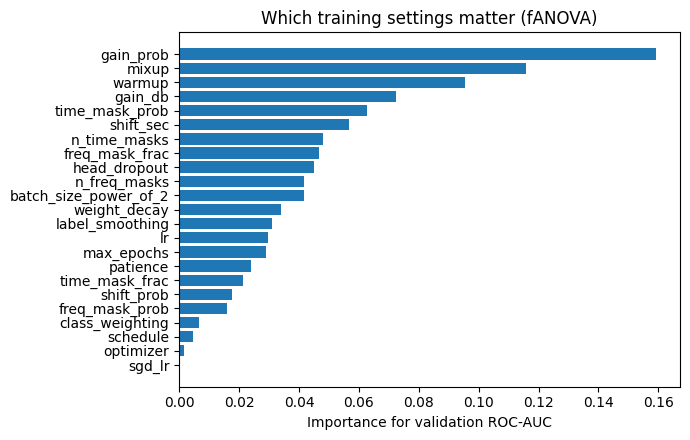

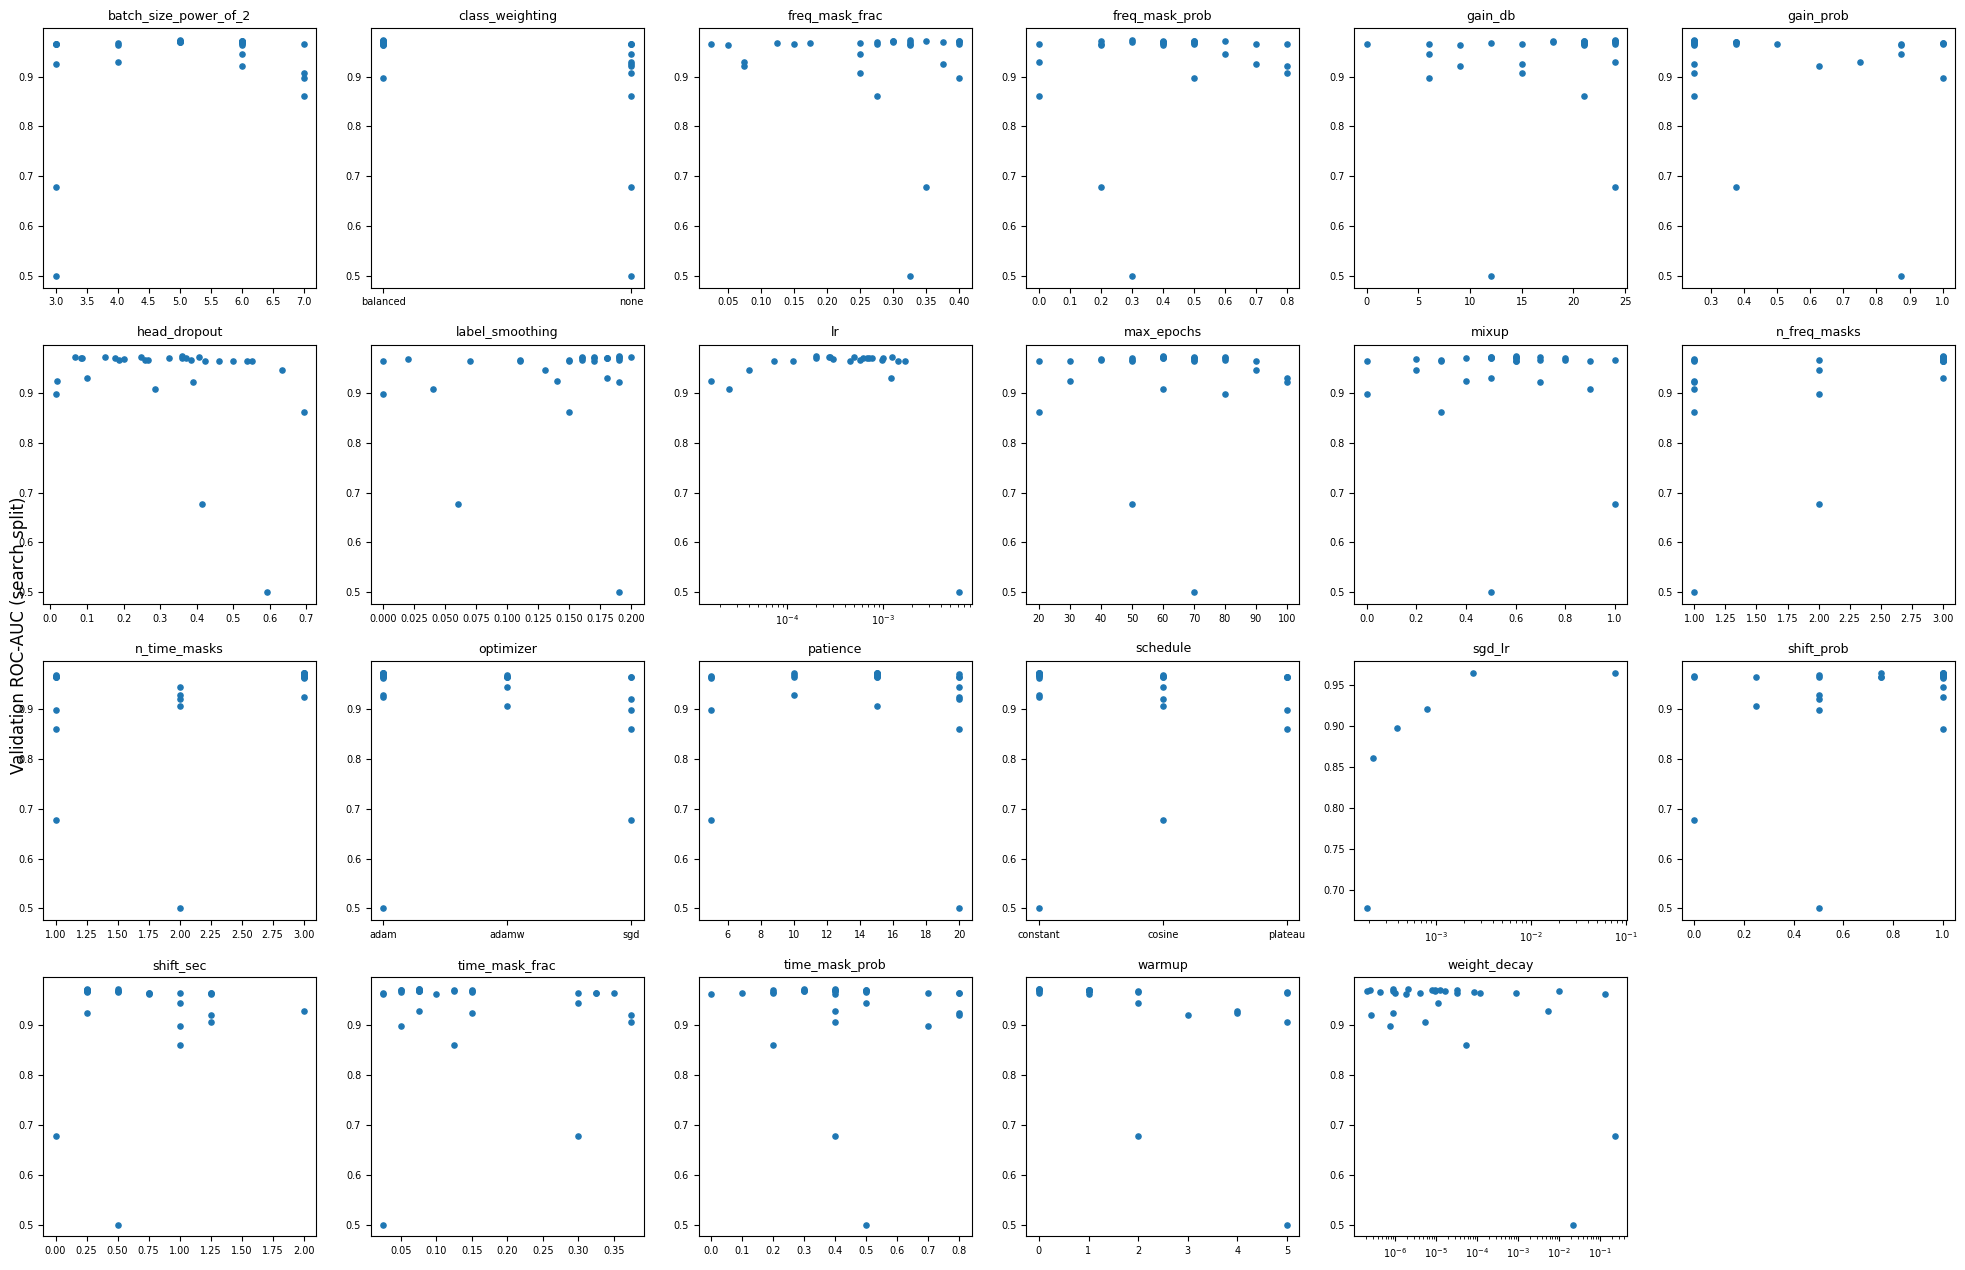

In [9]:
# Which settings matter? Importance of each setting for the validation ROC-AUC (fANOVA), plus each
# setting plotted against the score.
if int((trials["state"] == "COMPLETE").sum()) >= 5:
    importance = optuna.importance.get_param_importances(study)
    imp = pd.DataFrame({"setting": list(importance), "importance": list(importance.values())})
    imp.to_csv(os.path.join(OUT_DIR, "setting_importance.csv"), index=False)
    print("Importance of each setting for validation ROC-AUC (sums to 1):")
    print(imp.round(3).to_string(index=False))
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(imp["setting"][::-1], imp["importance"][::-1])
    ax.set_xlabel("Importance for validation ROC-AUC")
    ax.set_title("Which training settings matter (fANOVA)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "figure_setting_importance.png"), dpi=200)
    plt.show()

    params = [c for c in complete.columns if c.startswith("params_")]
    n_cols = 6
    fig, axes = plt.subplots(math.ceil(len(params) / n_cols), n_cols, figsize=(20, 3.2 * math.ceil(len(params) / n_cols)))
    for ax, col in zip(axes.flat, params):
        x = complete[col]
        if col in ("params_lr", "params_sgd_lr", "params_weight_decay"):
            ax.set_xscale("log")
        ax.scatter(x.astype(str) if x.dtype == object else x, complete["value"], s=14)
        ax.set_title(col.replace("params_", ""), fontsize=9)
        ax.tick_params(labelsize=7)
    for ax in list(axes.flat)[len(params):]:
        ax.axis("off")
    fig.supylabel("Validation ROC-AUC (search split)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "figure_setting_vs_score.png"), dpi=200)
    plt.show()

## 5. Stage 2: confirm on the Run 2 splits

The search scores each setting on one split, and the best of many tries is usually a little lucky. So the best `TOP_K` settings, and the Run 2 settings, are each trained again on the three Run 2 splits. Each run is also given the loudness check (validation clips with the level shifted by ±10 dB) at both operating points, with each threshold held fixed. Finished runs are skipped on rerun.

In [10]:
def choose_threshold(y, p, target):
    ok = [t for t in np.round(np.arange(0.01, 0.995, 0.005), 3)
          if recall_score(y, (p >= t).astype(int), zero_division=0) >= target]
    return float(max(ok)) if ok else 0.5


candidates = {"run2_settings": RUN2_B8}
for _, row in complete.iterrows():                 # best first; skip settings identical to ones already listed
    cfg = study.trials[int(row["number"])].user_attrs["config"]
    if any(cfg == c for c in candidates.values()):
        continue
    candidates[f"trial_{int(row['number'])}"] = cfg
    if len(candidates) == TOP_K + 1:
        break
print("Settings to confirm:", list(candidates))

for seed in CONFIRM_SEEDS:
    split = make_split(seed)
    for name, cfg in candidates.items():
        path = os.path.join(OUT_DIR, "confirm", f"{name}_seed{seed}.json")
        if os.path.exists(path):
            print(f"skip (done): {name}_seed{seed}")
            continue
        t0 = time.time()
        model, best, history, val_loader, criterion = train_cfg(cfg, seed, split)
        y = best["y_val"]
        shifted = {off: run_epoch(model, val_loader, cfg, criterion, level_offset_db=float(off))[1] for off in (-10, 10)}
        result = {"candidate": name, "seed": seed, "config": cfg, "best_epoch": best["epoch"], "epochs_run": len(history),
                  "minutes": (time.time() - t0) / 60, "val_roc_auc": roc_auc_score(y, best["p_val"]),
                  "val_accuracy_at_0.5": accuracy_score(y, best["p_val"] >= 0.5),
                  "val_distress_f1_at_0.5": f1_score(y, best["p_val"] >= 0.5, zero_division=0)}
        recall_changes, false_alarm_changes = [], []
        for t in TARGET_RECALLS:
            th = choose_threshold(y, best["p_val"], t)
            flagged = best["p_val"] >= th
            result[f"threshold_{t:.2f}"] = th
            result[f"val_recall_{t:.2f}"] = float(flagged[y == 1].mean())
            result[f"val_false_alarms_{t:.2f}"] = float(flagged[y == 0].mean())
            for p in shifted.values():
                recall_changes.append(abs((p >= th)[y == 1].mean() - flagged[y == 1].mean()))
                false_alarm_changes.append(abs((p >= th)[y == 0].mean() - flagged[y == 0].mean()))
        result["recall_change_10dB"] = float(max(recall_changes))
        result["false_alarm_change_10dB"] = float(max(false_alarm_changes))
        json.dump(result, open(path, "w"), indent=1, default=float)
        print(f"DONE {name}_seed{seed}: val AUC {result['val_roc_auc']:.4f} | acc@0.5 {result['val_accuracy_at_0.5']:.4f} | "
              f"false alarms at 0.90 / 0.95 recall {result['val_false_alarms_0.90']:.4f} / {result['val_false_alarms_0.95']:.4f} | "
              f"{result['minutes']:.1f} min")
        del model

Settings to confirm: ['run2_settings', 'trial_3', 'trial_47', 'trial_38']
skip (done): run2_settings_seed7
skip (done): trial_3_seed7
skip (done): trial_47_seed7
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 128MB/s]


DONE trial_38_seed7: val AUC 0.9616 | acc@0.5 0.9166 | false alarms at 0.90 / 0.95 recall 0.0941 / 0.2134 | 6.6 min
DONE run2_settings_seed21: val AUC 0.9723 | acc@0.5 0.9172 | false alarms at 0.90 / 0.95 recall 0.0711 / 0.1354 | 6.4 min
DONE trial_3_seed21: val AUC 0.9668 | acc@0.5 0.9262 | false alarms at 0.90 / 0.95 recall 0.0660 / 0.1235 | 6.8 min
DONE trial_47_seed21: val AUC 0.9689 | acc@0.5 0.9161 | false alarms at 0.90 / 0.95 recall 0.0660 / 0.1235 | 4.0 min
DONE trial_38_seed21: val AUC 0.9698 | acc@0.5 0.8971 | false alarms at 0.90 / 0.95 recall 0.0846 / 0.1421 | 4.5 min
DONE run2_settings_seed42: val AUC 0.9692 | acc@0.5 0.9253 | false alarms at 0.90 / 0.95 recall 0.0581 / 0.1333 | 4.6 min
DONE trial_3_seed42: val AUC 0.9657 | acc@0.5 0.9143 | false alarms at 0.90 / 0.95 recall 0.0650 / 0.1504 | 6.8 min
DONE trial_47_seed42: val AUC 0.9648 | acc@0.5 0.9154 | false alarms at 0.90 / 0.95 recall 0.0752 / 0.1744 | 3.7 min
DONE trial_38_seed42: val AUC 0.9566 | acc@0.5 0.9220 | f

## 6. Stage 3: decide

The rule was fixed before the search: a tuned setting replaces the Run 2 settings only if its mean validation ROC-AUC over the three splits is higher, it is higher on at least 2 of the 3 splits, and its recall and false-alarm rate both stay within 0.10 at ±10 dB at both operating points. Among settings that pass, the one with the highest mean ROC-AUC is chosen. If none passes, the Run 2 settings are kept, and the paper can state that tuning did not improve on them.

In [11]:
def pm(s, digits=4):
    s = pd.Series(s, dtype=float)
    return f"{s.mean():.{digits}f} ± {s.std(ddof=1):.{digits}f}" if len(s) > 1 else f"{s.mean():.{digits}f}"


conf = pd.DataFrame([json.load(open(p)) for p in glob.glob(os.path.join(OUT_DIR, "confirm", "*.json"))])
conf = conf[conf["candidate"].isin(candidates) & conf["seed"].isin(CONFIRM_SEEDS)]
ref_auc = conf[conf["candidate"] == "run2_settings"].set_index("seed")["val_roc_auc"]
table = []
for name in candidates:
    g = conf[conf["candidate"] == name].set_index("seed")
    common = g.index.intersection(ref_auc.index)
    diff = g.loc[common, "val_roc_auc"] - ref_auc.loc[common]
    robust = max(g["recall_change_10dB"].max(), g["false_alarm_change_10dB"].max()) <= LEVEL_TOLERANCE
    table.append({"Settings": name, "Seeds": len(g), "ROC-AUC": pm(g["val_roc_auc"]),
                  "Accuracy @0.5": pm(g["val_accuracy_at_0.5"]), "Distress F1 @0.5": pm(g["val_distress_f1_at_0.5"]),
                  **{f"False alarms @{t:.2f} recall": pm(g[f"val_false_alarms_{t:.2f}"]) for t in TARGET_RECALLS},
                  "ROC-AUC change vs Run 2 settings": round(diff.mean(), 4) if name != "run2_settings" else 0.0,
                  "Seeds better than Run 2 settings": int((diff > 0).sum()) if name != "run2_settings" else None,
                  "Loudness condition met": robust, "_mean_auc": g["val_roc_auc"].mean(), "_wins": int((diff > 0).sum()),
                  "_mean_diff": diff.mean()})
table = pd.DataFrame(table)
table.drop(columns=[c for c in table if c.startswith("_")]).to_csv(os.path.join(OUT_DIR, "confirmation_results.csv"), index=False)
print("CONFIRMATION on the Run 2 splits (validation results)")
print(table.drop(columns=[c for c in table if c.startswith("_")]).to_string(index=False))

need_wins = math.ceil(len(CONFIRM_SEEDS) * 2 / 3)
passing = table[(table["Settings"] != "run2_settings") & (table["_mean_diff"] > 0) &
                (table["_wins"] >= need_wins) & table["Loudness condition met"]]
if len(passing):
    winner = passing.sort_values("_mean_auc", ascending=False).iloc[0]["Settings"]
    decision = f"Tuned settings {winner} replace the Run 2 settings."
else:
    winner = "run2_settings"
    decision = "No tuned setting met the rule. The Run 2 settings are kept."
chosen = dict(candidates[winner])
record = {"decision": decision, "chosen": winner, "config": chosen, "search_trials": len(trials),
          "search_split_seed": TUNE_SEED, "confirm_seeds": CONFIRM_SEEDS, "lock_id": lock_id,
          "rule": f"mean validation ROC-AUC higher than the Run 2 settings, higher on at least {need_wins} of "
                  f"{len(CONFIRM_SEEDS)} splits, recall and false-alarm change at ±10 dB within {LEVEL_TOLERANCE} "
                  f"at recall targets {TARGET_RECALLS}"}
json.dump(record, open(os.path.join(OUT_DIR, "chosen_system_model_config.json"), "w"), indent=1, default=float)
print("\n" + decision)
print(pd.Series(chosen).to_string())
print("\nSaved chosen_system_model_config.json. The final evaluation notebook reads it.")
print("All results here are validation results. The locked test set and PVSD have not been used.")

CONFIRMATION on the Run 2 splits (validation results)
     Settings  Seeds         ROC-AUC   Accuracy @0.5 Distress F1 @0.5 False alarms @0.90 recall False alarms @0.95 recall  ROC-AUC change vs Run 2 settings  Seeds better than Run 2 settings  Loudness condition met
run2_settings      3 0.9704 ± 0.0017 0.9197 ± 0.0048  0.8867 ± 0.0088           0.0688 ± 0.0098           0.1344 ± 0.0010                            0.0000                               NaN                    True
      trial_3      3 0.9657 ± 0.0011 0.9216 ± 0.0064  0.8898 ± 0.0043           0.0627 ± 0.0048           0.1462 ± 0.0209                           -0.0047                               0.0                    True
     trial_47      3 0.9673 ± 0.0022 0.9149 ± 0.0015  0.8807 ± 0.0043           0.0734 ± 0.0067           0.1497 ± 0.0255                           -0.0031                               0.0                    True
     trial_38      3 0.9627 ± 0.0066 0.9119 ± 0.0131  0.8748 ± 0.0148           0.0829 ± 0